In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils.validation import check_array, check_is_fitted

SEED = 42
TARGET = "Target_local_recurrence"
pd.set_option("display.max_columns", None)
warnings.simplefilter("error", ConvergenceWarning)
print(f"numpy {np.__version__}; pandas {pd.__version__}; scikit-learn {sklearn.__version__}")

numpy 2.5.3; pandas 3.0.6; scikit-learn 1.9.1


In [2]:
analytic = pd.read_csv("../w4/analytic_table.csv")
test_membership = pd.read_csv("../w5/test.csv", usecols=["Patient_ID", TARGET])
previous_train_ids = pd.read_csv("../w5/train.csv", usecols=["Patient_ID"])["Patient_ID"]
assert analytic.Patient_ID.is_unique and test_membership.Patient_ID.is_unique
assert set(previous_train_ids).isdisjoint(test_membership.Patient_ID)
assert set(previous_train_ids) | set(test_membership.Patient_ID) == set(analytic.Patient_ID)
assert analytic.set_index("Patient_ID").loc[test_membership.Patient_ID, TARGET].tolist() == test_membership[TARGET].tolist()

pool = analytic.loc[analytic.Patient_ID.isin(previous_train_ids)].copy()
train, validation = train_test_split(pool, test_size=0.2, stratify=pool[TARGET], random_state=SEED)
train = train.sort_values("Patient_ID").reset_index(drop=True)
validation = validation.sort_values("Patient_ID").reset_index(drop=True)
assert set(train.Patient_ID).isdisjoint(validation.Patient_ID)
assert set(train.Patient_ID) | set(validation.Patient_ID) == set(previous_train_ids)
repeat_train, repeat_validation = train_test_split(pool, test_size=0.2, stratify=pool[TARGET], random_state=SEED)
assert set(repeat_train.Patient_ID) == set(train.Patient_ID)
assert set(repeat_validation.Patient_ID) == set(validation.Patient_ID)

samples = {"Обучение": train, "Валидация": validation, "Тест (отложен)": test_membership}
display(pd.DataFrame({name: {"Пациентов": len(frame), "Исход 1": int(frame[TARGET].sum())}
                      for name, frame in samples.items()}).T)
for name, frame in samples.items():
    print(f"{name}: {sorted(frame.Patient_ID.tolist())}")

,Пациентов,Исход 1
Обучение,84,7
Валидация,21,2
Тест (отложен),35,3


Обучение: [1, 7, 8, 9, 10, 11, 13, 15, 19, 20, 22, 23, 25, 26, 27, 32, 35, 37, 42, 46, 49, 51, 52, 54, 57, 58, 59, 60, 61, 62, 63, 65, 66, 67, 68, 72, 73, 74, 75, 78, 79, 83, 84, 86, 87, 91, 93, 94, 97, 98, 101, 102, 104, 105, 108, 109, 111, 115, 116, 117, 118, 121, 122, 124, 125, 131, 132, 133, 137, 138, 144, 146, 150, 159, 169, 178, 179, 194, 196, 276, 285, 293, 302, 312]
Валидация: [5, 6, 12, 24, 38, 41, 43, 45, 56, 64, 89, 90, 103, 106, 120, 123, 141, 143, 154, 158, 273]
Тест (отложен): [2, 4, 21, 29, 31, 34, 39, 44, 47, 48, 55, 69, 70, 77, 80, 82, 85, 95, 99, 100, 107, 113, 114, 119, 128, 135, 136, 139, 140, 142, 152, 156, 170, 174, 313]


In [3]:
binary = ["Gender", "Induction_Chemotherapy", "Concurrent_chemotherapy"]
ordinal = ["T_category", "N_category", "AJCC_Stage", "Pathological_grade"]
nominal = ["Race", "Tumor_side", "Tumor_subsite", "Smoking_status_at_diagnosis"]
quantitative = [col for col in pool if col not in ["Patient_ID", TARGET] + binary + ordinal + nominal]
features = quantitative + ordinal + binary + nominal
X_train, y_train = train[features], train[TARGET]
X_validation, y_validation = validation[features], validation[TARGET]
assert len(features) == 31 and len(quantitative) == 20

ordinal_codes = {
    "T_category": {1: 1, 2: 2, 3: 3, 4: 4},
    "N_category": {"0": 0, "1": 1, "2a": 2, "2b": 3, "2c": 4, "3": 5},
    "AJCC_Stage": {"I": 1, "II": 2, "III": 3, "IV": 4},
    "Pathological_grade": {"I": 1, "I-II": 1.5, "II": 2, "II-III": 2.5, "III": 3, "IV": 4},
}
binary_codes = {"Gender": {"Female": 0, "Male": 1},
                "Induction_Chemotherapy": {"N": 0, "Y": 1},
                "Concurrent_chemotherapy": {"N": 0, "Y": 1}}

def encode_ordinal(frame):
    return pd.DataFrame({col: frame[col].map(ordinal_codes[col]) for col in frame}, index=frame.index)

def encode_binary(frame):
    return pd.DataFrame({col: frame[col].map(binary_codes[col]) for col in frame}, index=frame.index)

def grade_missing(frame):
    return frame.isna().astype(float)

class OutlierAwareScaler(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        values = check_array(X, dtype=float)
        self.n_features_in_ = values.shape[1]
        self.n_samples_seen_ = values.shape[0]
        q1, q3 = np.quantile(values, [0.25, 0.75], axis=0)
        iqr = q3 - q1
        self.outlier_counts_ = ((values < q1 - 1.5 * iqr)
                               | (values > q3 + 1.5 * iqr)).sum(axis=0)
        self.robust_mask_ = self.outlier_counts_ > 0
        if np.any(iqr[self.robust_mask_] <= 0):
            raise ValueError("Нулевой межквартильный размах у признака с выбросами")
        standard = StandardScaler().fit(values)
        self.center_ = np.where(self.robust_mask_, np.median(values, axis=0), standard.mean_)
        self.scale_ = np.where(self.robust_mask_, iqr, standard.scale_)
        return self

    def transform(self, X):
        check_is_fitted(self, ["center_", "scale_"])
        values = check_array(X, dtype=float)
        if values.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков не совпадает с обучающей выборкой")
        return (values - self.center_) / self.scale_


numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
quantitative_preparation = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", OutlierAwareScaler()),
])
preparation = ColumnTransformer([
    ("quantitative", quantitative_preparation, quantitative),
    ("ordinal", Pipeline([
        ("encode", FunctionTransformer(encode_ordinal, feature_names_out="one-to-one")),
        ("numeric", clone(numeric)),
    ]), ordinal),
    ("binary", Pipeline([
        ("encode", FunctionTransformer(encode_binary, feature_names_out="one-to-one")),
        ("impute", SimpleImputer(strategy="most_frequent")),
    ]), binary),
    ("nominal", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(min_frequency=5, drop="first", handle_unknown="infrequent_if_exist", sparse_output=False)),
    ]), nominal),
    ("grade_missing", FunctionTransformer(grade_missing, feature_names_out="one-to-one"), ["Pathological_grade"]),
], remainder="drop")

display(pd.DataFrame({"Группа": ["Количественные", "Порядковые", "Бинарные", "Номинальные"],
                      "Число исходных признаков": [len(quantitative), len(ordinal), len(binary), len(nominal)]}))

,Группа,Число исходных признаков
0,Количественные,20
1,Порядковые,4
2,Бинарные,3
3,Номинальные,4


In [4]:
C = 0.1
MAX_ITER = 2000
HIDDEN = (16,)
sample_weight = compute_sample_weight("balanced", y_train)

def network(activation, random_state):
    # alpha = 1 / C: та же сила L2-штрафа на объект, что у логистической регрессии
    return MLPClassifier(hidden_layer_sizes=HIDDEN, activation=activation, solver="lbfgs",
                         alpha=1 / C, max_iter=MAX_ITER, random_state=random_state)

def fit(classifier):
    model = Pipeline([("prepare", clone(preparation)), ("classifier", classifier)])
    model.fit(X_train, y_train, classifier__sample_weight=sample_weight)
    fitted = model.named_steps["prepare"].named_transformers_["quantitative"]
    assert np.allclose(fitted.named_steps["impute"].statistics_, X_train[quantitative].median().to_numpy())
    assert int(fitted.named_steps["scale"].n_samples_seen_) == len(train)
    return model

def iterations(model):
    return int(np.max(model.named_steps["classifier"].n_iter_))

classifiers = {
    "Логистическая регрессия": LogisticRegression(C=C, max_iter=MAX_ITER, random_state=SEED),
    "Нейронная сеть (ReLU)": network("relu", SEED),
}
models = {name: fit(classifier) for name, classifier in classifiers.items()}

parameter_names = ["hidden_layer_sizes", "activation", "solver", "C", "alpha", "max_iter", "random_state"]
summary = pd.DataFrame({name: {key: model.named_steps["classifier"].get_params().get(key, "—")
                               for key in parameter_names}
                        for name, model in models.items()}).T
summary["Признаков на входе"] = [model.named_steps["prepare"].transform(X_validation).shape[1] for model in models.values()]
summary["Итераций до остановки"] = [iterations(model) for model in models.values()]
display(summary)
assert all(iterations(model) < MAX_ITER for model in models.values())

,hidden_layer_sizes,activation,solver,C,alpha,max_iter,random_state,Признаков на входе,Итераций до остановки
Логистическая регрессия,—,—,lbfgs,0.1,—,2000,42,36,15
Нейронная сеть (ReLU),"(16,)",relu,lbfgs,—,10.0,2000,42,36,231


In [5]:
models["Нейронная сеть без нелинейности (f(x) = x)"] = fit(network("identity", SEED))
linear = models["Нейронная сеть без нелинейности (f(x) = x)"].named_steps["classifier"]
assert linear.activation == "identity" and linear.hidden_layer_sizes == HIDDEN
assert iterations(models["Нейронная сеть без нелинейности (f(x) = x)"]) < MAX_ITER

y_validation_array = y_validation.to_numpy()
accuracy = pd.DataFrame({
    name: {"Доля верных ответов: обучение": accuracy_score(y_train, model.predict(X_train)),
           "Доля верных ответов: валидация": accuracy_score(y_validation, model.predict(X_validation)),
           "Итераций до остановки": iterations(model)}
    for name, model in models.items()
}).T
accuracy["Итераций до остановки"] = accuracy["Итераций до остановки"].astype(int)
display(accuracy.round(4))

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Ориентир «всегда нет рецидива»: обучение {baseline.score(X_train, y_train):.4f}, "
      f"валидация {baseline.score(X_validation, y_validation):.4f}")
for name, model in models.items():
    predicted = model.predict(X_validation)
    print(f"{name}: на валидации предсказано рецидивов {int(predicted.sum())}, "
          f"из них верно {int((predicted & y_validation_array).sum())} из {int(y_validation_array.sum())}")

,Доля верных ответов: обучение,Доля верных ответов: валидация,Итераций до остановки
Логистическая регрессия,0.9048,0.7619,15
Нейронная сеть (ReLU),0.9286,0.7619,231
Нейронная сеть без нелинейности (f(x) = x),0.9048,0.8095,21


Ориентир «всегда нет рецидива»: обучение 0.9167, валидация 0.9048
Логистическая регрессия: на валидации предсказано рецидивов 3, из них верно 0 из 2
Нейронная сеть (ReLU): на валидации предсказано рецидивов 3, из них верно 0 из 2
Нейронная сеть без нелинейности (f(x) = x): на валидации предсказано рецидивов 2, из них верно 0 из 2


In [6]:
seeds = list(range(20))
seed_models = {seed: fit(network("relu", seed)) for seed in seeds}
assert all(iterations(model) < MAX_ITER for model in seed_models.values())
seed_results = pd.DataFrame({
    seed: {"Доля верных ответов: обучение": accuracy_score(y_train, model.predict(X_train)),
           "Доля верных ответов: валидация": accuracy_score(y_validation, model.predict(X_validation)),
           "Итераций до остановки": iterations(model)}
    for seed, model in seed_models.items()
}).T.rename_axis("random_state")
seed_results["Итераций до остановки"] = seed_results["Итераций до остановки"].astype(int)
display(seed_results.round(4))
display(seed_results.drop(columns="Итераций до остановки").agg(["mean", "std", "min", "max"]).round(4))

validation_predictions = np.array([model.predict(X_validation) for model in seed_models.values()])
validation_probabilities = np.array([model.predict_proba(X_validation)[:, 1] for model in seed_models.values()])
logistic_prediction = models["Логистическая регрессия"].predict(X_validation)
print(f"Сетей: {len(seed_models)}; итераций до остановки: от {seed_results['Итераций до остановки'].min()} "
      f"до {seed_results['Итераций до остановки'].max()} при максимуме {MAX_ITER}")
print(f"Различных наборов предсказаний на валидации: {len(np.unique(validation_predictions, axis=0))}")
print(f"Сетей с теми же предсказаниями на валидации, что у логистической регрессии: "
      f"{int((validation_predictions == logistic_prediction).all(axis=1).sum())} из {len(seed_models)}")
print(f"Наибольший разброс вероятности рецидива у одного пациента валидации между сетями: "
      f"{(validation_probabilities.max(axis=0) - validation_probabilities.min(axis=0)).max():.4f}")

,Доля верных ответов: обучение,Доля верных ответов: валидация,Итераций до остановки
random_state,,,
0,0.9286,0.7619,170
1,0.9286,0.7619,186
2,0.9286,0.7619,345
3,0.9286,0.7619,145
4,0.9286,0.7619,216
5,0.9286,0.7619,189
6,0.9167,0.7619,213
7,0.9286,0.7619,210
8,0.9286,0.7619,181


,Доля верных ответов: обучение,Доля верных ответов: валидация
mean,0.9268,0.7619
std,0.0044,0.0000
min,0.9167,0.7619
max,0.9286,0.7619


Сетей: 20; итераций до остановки: от 139 до 345 при максимуме 2000
Различных наборов предсказаний на валидации: 1
Сетей с теми же предсказаниями на валидации, что у логистической регрессии: 20 из 20
Наибольший разброс вероятности рецидива у одного пациента валидации между сетями: 0.0417


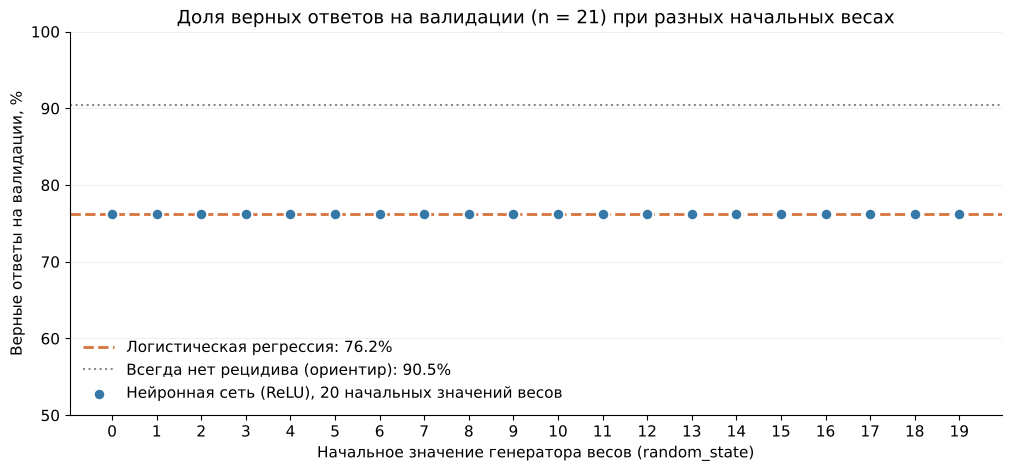

In [7]:
logistic_validation = accuracy.loc["Логистическая регрессия", "Доля верных ответов: валидация"]
baseline_validation = baseline.score(X_validation, y_validation)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
ax.axhline(logistic_validation * 100, color="#D7743B", linewidth=2, linestyle="--", zorder=1,
           label=f"Логистическая регрессия: {logistic_validation:.1%}")
ax.axhline(baseline_validation * 100, color="#8A8A8A", linewidth=1.5, linestyle=":", zorder=1,
           label=f"Всегда нет рецидива (ориентир): {baseline_validation:.1%}")
ax.scatter(seed_results.index, seed_results["Доля верных ответов: валидация"] * 100, s=70,
           color="#3678A8", edgecolor="white", linewidth=1.5, zorder=3,
           label=f"Нейронная сеть (ReLU), {len(seeds)} начальных значений весов")
ax.set(xlabel="Начальное значение генератора весов (random_state)",
       ylabel="Верные ответы на валидации, %", xticks=seeds,
       ylim=(50, 100), yticks=np.arange(50, 101, 10),
       title=f"Доля верных ответов на валидации (n = {len(validation)}) при разных начальных весах")
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False, loc="lower left")
plt.show()

## Выводы

На валидации (21 пациент, 2 рецидива) нейронная сеть с 16 нейронами ReLU не лучше логистической регрессии: у обеих доля верных ответов 0,762, предсказания совпадают, и ни одна не нашла ни одного из двух рецидивов. Обе уступают постоянному прогнозу «нет рецидива» (0,905), то есть ошибки — в основном ложные тревоги.

Без нелинейности сеть становится линейной моделью: доля на обучении снижается с 0,929 до 0,905, а на валидации растёт до 0,810, потому что ложных тревог две вместо трёх. Нелинейность лишь точнее подгоняет обучающие данные и обобщение не улучшает.

От начальных весов результат почти не зависит: у 20 сетей доля на валидации одна и та же (0,762, стандартное отклонение 0), предсказания одинаковы, на обучении доля 0,917–0,929, а вероятность рецидива у пациента меняется не больше чем на 0,042. Все сети остановились за 139–345 итераций из 2000.

Признаки переобучения есть: разница долей на обучении и валидации 0,143 у логистической регрессии, 0,167 у сети и 0,095 у сети без нелинейности. Однако ошибка на одном пациенте валидации меняет долю на 0,048, поэтому различия между моделями в одного–двух пациентов ненадёжны.